# tiling

> Sliding-window tile coordinate computation and patch extraction.
>
> This module is **pure geometry** — no model, no GPU operations beyond tensor slicing.
> It depends only on `core` from this package.

In [ ]:
#| default_exp tiling

In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
#| hide
from nbdev.showdoc import *

In [4]:
#| export
#from __future__ import annotations

from nbdev.maker import import2relative
from loguru import logger
import math
from typing import List
import cv2
from typing import Tuple, Union, Optional
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
from pathlib import Path

In [5]:
#| export
import torch
from torch import Tensor


In [ ]:
#| exporti
from segmentation_tools_pt.tiling_core import PatchCoords, TileConfig


In [7]:
#| export
#logger = logging.getLogger(__name__)

NameError: name 'logging' is not defined

## Coordinate computation

In [8]:
#| export
#def compute_patch_coords(
    #h: int, # image height in pixels (after padding)
    #w: int, # image width in pixels (after padding)
    #patch_size: int, # side length of each square tile
    #overlap: int, # pixel overlap between adjacent tiles
#) -> List[PatchCoords]:
    #"""Enumerate all tile positions for a sliding window over an ``(H, W)`` grid.

    #"""
    #if h < patch_size:
        #raise ValueError(f"Image height {h} < patch_size {patch_size}. Pad first.")
    #if w < patch_size:
        #raise ValueError(f"Image width {w} < patch_size {patch_size}. Pad first.")

    #stride = patch_size - overlap

    ## Number of steps: ceil so we always cover the full extent
    #n_rows = math.ceil((h - patch_size) / stride) + 1
    #n_cols = math.ceil((w - patch_size) / stride) + 1

    #coords: List[PatchCoords] = []
    #for row in range(n_rows):
        #for col in range(n_cols):
            #y_start = min(row * stride, h - patch_size)
            #x_start = min(col * stride, w - patch_size)
            #coords.append(
                #PatchCoords(
                    #y_start=y_start,
                    #y_end=y_start + patch_size,
                    #x_start=x_start,
                    #x_end=x_start + patch_size,
                #)
            #)

    #logger.debug(
        #"compute_patch_coords: (%d×%d) patch=%d overlap=%d → %d tiles (%d×%d grid)",
        #h, w, patch_size, overlap, len(coords), n_rows, n_cols,
    #)
    #return coords

In [9]:
#coords_ =compute_patch_coords(
    #h=512, 
    #w=512, 
    #patch_size=256, 
    #overlap=64
#)
#coords_

2026-03-19 10:59:19.753 | DEBUG    | __main__:compute_patch_coords:36 - compute_patch_coords: (%d×%d) patch=%d overlap=%d → %d tiles (%d×%d grid)


[PatchCoords(y=0:256, x=0:256),
 PatchCoords(y=0:256, x=192:448),
 PatchCoords(y=0:256, x=256:512),
 PatchCoords(y=192:448, x=0:256),
 PatchCoords(y=192:448, x=192:448),
 PatchCoords(y=192:448, x=256:512),
 PatchCoords(y=256:512, x=0:256),
 PatchCoords(y=256:512, x=192:448),
 PatchCoords(y=256:512, x=256:512)]

## Patch extraction

In [10]:
#| export
#def extract_patches(
    #image: Tensor, # Float tensor of shape (B, C, H, W). Only B=1 supported (single-image tiling).
    #coords: List[PatchCoords], # List of tile coordinates from compute_patch_coords.
#) -> Tensor:
    #"""Crop ``image`` at each position in ``coords`` and stack into a batch.

    #"""
    #if image.shape[0] != 1:
        #raise ValueError(
            #f"extract_patches expects batch size 1, got {image.shape[0]}. "
            #"Process images one at a time."
        #)

    #patches = torch.stack(
        #[
            #image[0, :, c.y_start:c.y_end, c.x_start:c.x_end]
            #for c in coords
        #],
        #dim=0,
    #)  # (N, C, patch_size, patch_size)

    #logger.debug("extract_patches: %d patches, shape %s", len(coords), tuple(patches.shape))
    #return patches

In [11]:
#img = torch.randn(1, 3, 512, 512)
#patches = extract_patches(img, coords_)
#patches.shape


2026-03-19 10:59:20.644 | DEBUG    | __main__:extract_patches:23 - extract_patches: %d patches, shape %s


torch.Size([9, 3, 256, 256])

## Convenience wrapper

In [12]:
#| export
#class TileProcessor(
    #torch.nn.Module
    #):
    #"""Stateless :class:`torch.nn.Module` that tiles an image into patches.

    #Wrapping the tiling step in an ``nn.Module`` lets it participate in
    #``nn.Sequential`` pipelines and in ONNX tracing if needed.

    #.. warning::
        #Returns a Python list alongside the tensor, so this class is **not**
        #directly ONNX-exportable. Use :class:`~segmentation_tools_pt.model_wrapper.TiledModel`
        #for ONNX export — it bakes all shapes statically.
    #"""

    #def __init__(
        #self, 
        #tile_cfg: TileConfig # Configuration for tiling
        #) -> None:
        #super().__init__()
        #self.tile_cfg = tile_cfg

    #def forward(
        #self, 
        #x: Tensor):
        #"""Tile image ``x``.

        #Returns:
            #Tuple of ``(patches, coords, pad_ltrb)``.
        #"""
        #from segmentation_tools_pt.tiling_core import pad_to_divisible

        #padded, pad_ltrb = pad_to_divisible(x, self.tile_cfg)
        #h, w = padded.shape[-2], padded.shape[-1]
        #coords = compute_patch_coords(h, w, self.tile_cfg.patch_size, self.tile_cfg.overlap)
        #patches = extract_patches(padded, coords)
        #return patches, coords, pad_ltrb

## ONNX opset 12 compatible TileProcessor

Fixed input size, returns only tensor. The fixed-length loop is unrolled by the tracer into Slice + Concat — fully opset 12 compatible.

In [23]:
#--- reading ----
im_path = Path(r"/home/ai_dsx.work/data/projects/goni/hochstrom_pin_ets/1C_Typ150/Incoming/Incoming_unzip/main_im2_cropped")
RAW_DIR=Path(r'/home/ai_dsx.work/data/projects/goni/data/cegled_econo/segmentation/')
IM_PATH = Path(RAW_DIR, 'sm_imgs')
sm_im_path = Path(IM_PATH).ls()[0]
#sm_im_path = Path(im_path).ls()[0]
print(f'sample path exists: {sm_im_path.exists()}')
sm_img = cv2.imread(str(sm_im_path), cv2.IMREAD_GRAYSCALE)



sample path exists: True


In [ ]:
#| export
class TileProcessorONNX(
    torch.nn.Module # torch.nn.Module is a base class for all neural network modules in PyTorch.
    ):
    """
    ONNX opset 12 compatible PyTorch module for splitting images into overlapping tiles.
    Fixed input size — all positions pre-computed. Returns ONLY tensor (no list).
    The tracer unrolls the fixed-length loop into Slice + Concat ops.

    If ``input_h`` or ``input_w`` is smaller than ``tile_size`` the image is
    padded up to ``tile_size`` so that at least one full tile is always produced.
    """

    def __init__(
        self, 
        tile_size: int = 256,  # Side length of each square tile
        overlap: int = 32, # Pixel overlap between adjacent tiles 
        input_h: int = 1152, # Expected input height in pixels (after padding) 
        input_w: int = 1632, # Expected input width in pixels (after padding)
        debug: bool = False, # Whether to print debug info at init time (e.g. number of tiles, padding applied)
        ):
        super().__init__()
        self.tile_size = tile_size 
        self.overlap = overlap
        self.stride = tile_size - overlap
        self.input_h = input_h
        self.input_w = input_w
        self.debug = debug

        if self.debug:
            print(f"[TileProcessorONNX::__init__] Called with: tile_size={tile_size}, overlap={overlap}, input_h={input_h}, input_w={input_w}")

        self._setup_tile_layout(debug)

    def _compute_effective_size(self, input_h, input_w, tile_size, debug: bool = False):
        effective_h = max(input_h, tile_size)
        effective_w = max(input_w, tile_size)
        if debug:
            print(f"[TileProcessorONNX::_compute_effective_size] effective_h={effective_h}, effective_w={effective_w}")
        return effective_h, effective_w

    def _compute_num_tiles(self, effective_h, effective_w, stride, overlap, debug: bool = False):
        num_tiles_h = max(1, (effective_h - overlap + stride - 1) // stride)
        num_tiles_w = max(1, (effective_w - overlap + stride - 1) // stride)
        if debug:
            print(f"[TileProcessorONNX::_compute_num_tiles] num_tiles_h={num_tiles_h}, num_tiles_w={num_tiles_w}")
        return num_tiles_h, num_tiles_w

    def _compute_positions(self, num_tiles_h, num_tiles_w, stride, debug: bool = False):
        h_starts_list = []
        w_starts_list = []
        positions = []
        for i in range(num_tiles_h):
            for j in range(num_tiles_w):
                start_h = i * stride
                start_w = j * stride
                h_starts_list.append(start_h)
                w_starts_list.append(start_w)
                positions.append((i, j, start_h, start_w))
        if debug:
            print(f"[TileProcessorONNX::_compute_positions] Computed {len(positions)} positions")
        return h_starts_list, w_starts_list, positions

    def _setup_tile_layout(self, debug: bool = False):
        # Step 1: Calculate effective image size
        effective_h, effective_w = self._compute_effective_size(
            self.input_h, 
            self.input_w, 
            self.tile_size, 
            debug)

        # Step 2: Number of tiles
        self.num_tiles_h, self.num_tiles_w = self._compute_num_tiles(
            effective_h, 
            effective_w, 
            self.stride, 
            self.overlap, 
            debug)

        # Step 3: Pre-compute positions
        self.h_starts_list, self.w_starts_list, self.positions = self._compute_positions(
            self.num_tiles_h, 
            self.num_tiles_w, 
            self.stride, 
            debug
        )
        self.num_tiles = len(self.h_starts_list)

        # Step 4: Final padded size (must cover tiled grid)
        self.padded_h = self.num_tiles_h * self.stride + self.overlap
        self.padded_w = self.num_tiles_w * self.stride + self.overlap

        if debug:
            print(f"[TileProcessorONNX::_setup_tile_layout] Raw padded_h={self.padded_h}, padded_w={self.padded_w}")

        # Step 5: Ensure padded size >= tile_size (for input < tile_size)
        self.padded_h = max(self.padded_h, self.tile_size)
        self.padded_w = max(self.padded_w, self.tile_size)

        # Step 6: Padding needed
        self.pad_h = max(0, self.padded_h - self.input_h)
        self.pad_w = max(0, self.padded_w - self.input_w)

        if debug:
            print(f"[TileProcessorONNX::_setup_tile_layout] Final: tile_size={self.tile_size}, overlap={self.overlap}, stride={self.stride}")
            print(f"[TileProcessorONNX::_setup_tile_layout] Input: ({self.input_h}, {self.input_w})  Effective: ({effective_h}, {effective_w})")
            print(f"[TileProcessorONNX::_setup_tile_layout] Grid: {self.num_tiles_h}x{self.num_tiles_w} tiles, Total tiles: {self.num_tiles}")
            print(f"[TileProcessorONNX::_setup_tile_layout] Padding needed: (h={self.pad_h}, w={self.pad_w}), Final padded: ({self.padded_h}, {self.padded_w})")

    def forward(self, x: 'Tensor') -> 'Tensor':
        """
        Split input tensor into overlapping tiles.
        Uses constant slicing (ONNX opset 12 compatible).

        Args:
            x: Input tensor [B, C, H, W] — must be [B, C, input_h, input_w]

        Returns:
            Tensor of shape [N*B, C, tile_size, tile_size] where N is num_tiles.
            Access tile positions via ``self.positions``.
        """
        if self.debug:
            print(f"[TileProcessorONNX::forward] Input x.shape={x.shape}")

        if self.pad_h > 0 or self.pad_w > 0:
            if self.debug:
                print(f"[TileProcessorONNX::forward] Applying padding: (h={self.pad_h}, w={self.pad_w})")
            x = torch.nn.functional.pad(x, (0, self.pad_w, 0, self.pad_h), mode="constant", value=0)
            if self.debug:
                print(f"[TileProcessorONNX::forward] After padding x.shape={x.shape}")

        tiles = []
        for i in range(self.num_tiles):
            h_start = self.h_starts_list[i]
            w_start = self.w_starts_list[i]
            tile = x[:, :, h_start : h_start + self.tile_size, w_start : w_start + self.tile_size]
            if self.debug:
                print(f"[TileProcessorONNX::forward] Extracted tile {i}: h={h_start}, w={w_start}, tile.shape={tile.shape}")
            tiles.append(tile)
        out = torch.cat(tiles, dim=0)
        if self.debug:
            print(f"[TileProcessorONNX::forward] Output tiles shape: {out.shape}")
        return out

In [19]:
H,W = sm_img.shape[:2]
print(f'H: {H}, W: {W}')

H: 1152, W: 1632


In [24]:
#| eval: false
# ONNX opset 12 export test — run manually
import torch
from pathlib import Path
H,W = sm_img.shape[:2]
print(f'H: {H}, W: {W}')
#Path("outputs").mkdir(exist_ok=True)
proc = TileProcessorONNX(
    tile_size=256, 
    overlap=64, 
    input_h=H, 
    input_w=W,
    debug=True
)

x = sm_img
x = torch.from_numpy(x).unsqueeze(0).unsqueeze(0).float()
x.shape


H: 482, W: 577
[TileProcessorONNX::__init__] Called with: tile_size=256, overlap=64, input_h=482, input_w=577
[TileProcessorONNX::_compute_effective_size] effective_h=482, effective_w=577
[TileProcessorONNX::_compute_num_tiles] num_tiles_h=3, num_tiles_w=3
[TileProcessorONNX::_compute_positions] Computed 9 positions
[TileProcessorONNX::_setup_tile_layout] Raw padded_h=640, padded_w=640
[TileProcessorONNX::_setup_tile_layout] Final: tile_size=256, overlap=64, stride=192
[TileProcessorONNX::_setup_tile_layout] Input: (482, 577)  Effective: (482, 577)
[TileProcessorONNX::_setup_tile_layout] Grid: 3x3 tiles, Total tiles: 9
[TileProcessorONNX::_setup_tile_layout] Padding needed: (h=158, w=63), Final padded: (640, 640)


torch.Size([1, 1, 482, 577])

In [34]:
tiles = proc(x)
positions = proc.positions
print(f"Forward: {x.shape} -> {tiles.shape}")

Forward: torch.Size([1, 1, 1152, 1632]) -> torch.Size([40, 1, 256, 256])


In [ ]:
#| export
def visualize_tile_grid(
    tiles: Union[torch.Tensor, np.ndarray], # tensor or array of tiles
    positions: List[Tuple], # list of (row, col, start_h, start_w) for each tile
    max_tiles: int = 16, # maximum number of tiles to display
    figsize: Tuple[int, int] = (16, 12), # figure size
    save_path: Optional[Union[str, Path]] = None # path to save the visualization
) -> None:
    """
    Visualize individual tiles in a grid layout.
    
    """
    
    if isinstance(tiles, torch.Tensor):
        tiles = tiles.cpu().numpy()
    
    n_tiles = min(len(tiles), max_tiles)
    n_cols = int(np.ceil(np.sqrt(n_tiles)))
    n_rows = int(np.ceil(n_tiles / n_cols))
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=figsize)
    if n_rows == 1 and n_cols == 1:
        axes = [axes]
    elif n_rows == 1 or n_cols == 1:
        axes = axes.flatten()
    else:
        axes = axes.flatten()
    
    for i in range(n_tiles):
        # Handle different tile formats
        if len(tiles[i].shape) == 3:
            tile_img = tiles[i][0] if tiles[i].shape[0] == 1 else tiles[i]
        else:
            tile_img = tiles[i]
        
        axes[i].imshow(tile_img, cmap='gray')
        
        # Add detailed title with position info
        if i < len(positions):
            row, col, start_h, start_w = positions[i]
            title = f'Tile {i}\nRow:{row}, Col:{col}\nPos:({start_h},{start_w})'
        else:
            title = f'Tile {i}'
        
        axes[i].set_title(title, fontsize=10)
        axes[i].axis('off')
    
    # Hide empty subplots
    for i in range(n_tiles, len(axes)):
        axes[i].axis('off')
        axes[i].set_visible(False)
    
    plt.suptitle(f'Individual Tiles Grid (Showing {n_tiles}/{len(tiles)} tiles)', 
                 fontsize=16, fontweight='bold')
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"Saved: {save_path}")
    
    plt.show()

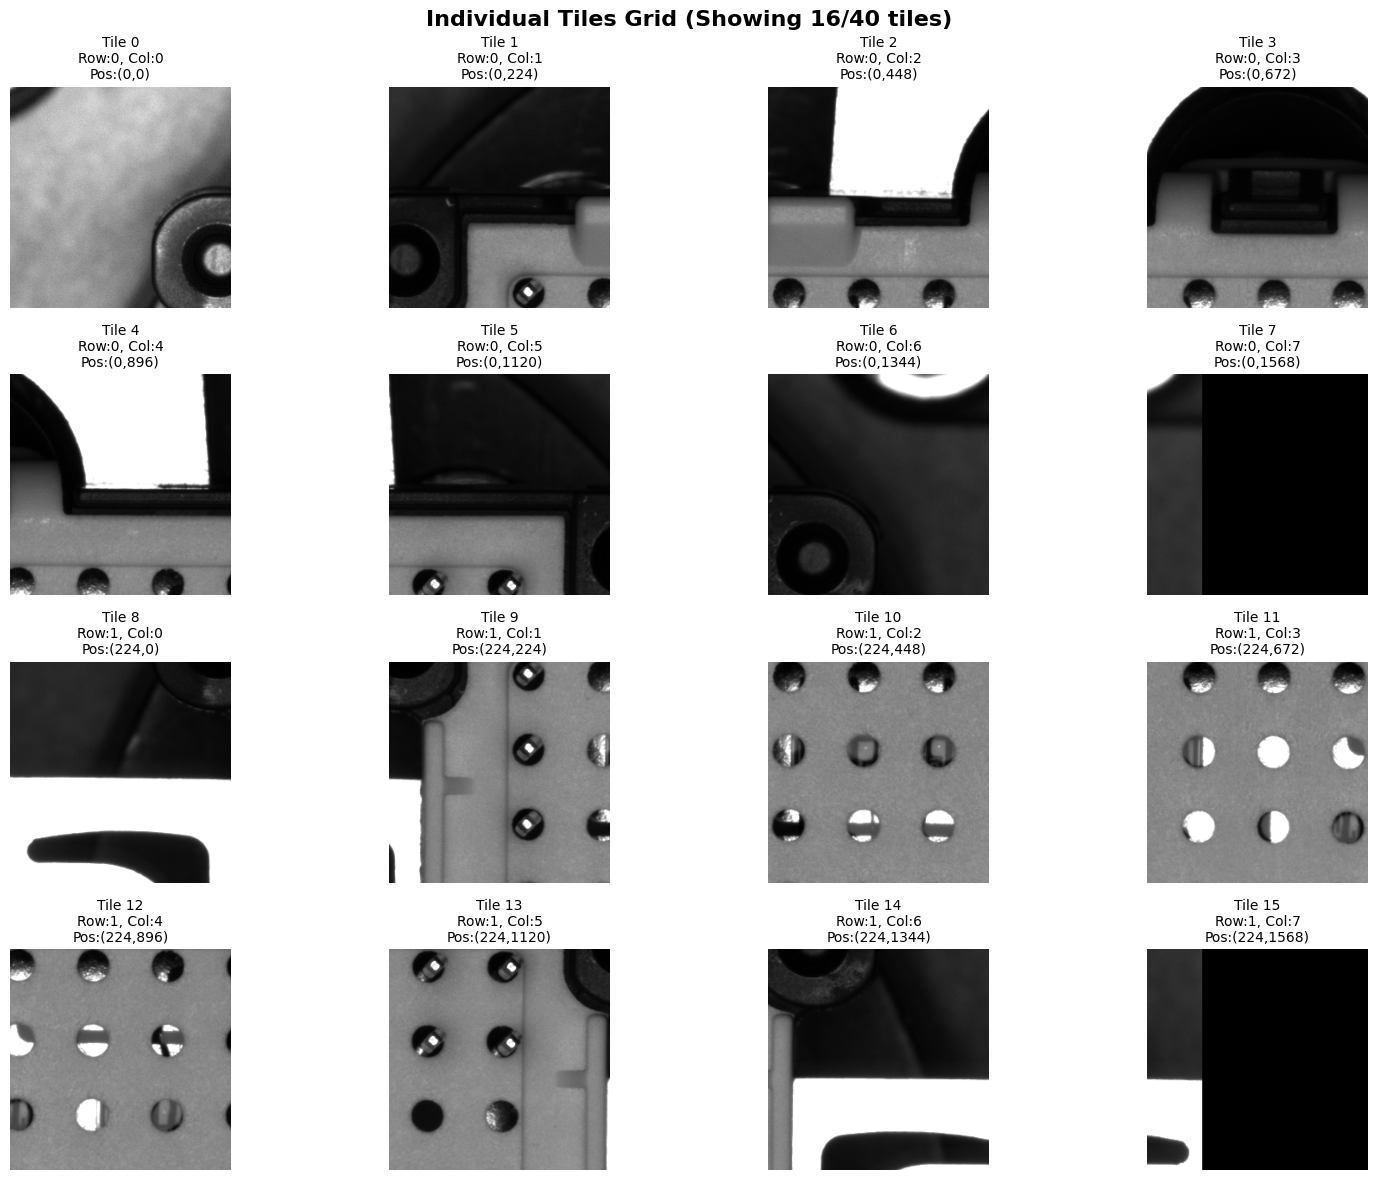

In [36]:
visualize_tile_grid(
    tiles=tiles,
    positions=positions,
    max_tiles=16,
    figsize=(16, 12),
    save_path=None
)

In [54]:
#| export
def visualize_tile_overlay(
    original_image: np.ndarray, # original image as numpy array
    tiles: Union[torch.Tensor, np.ndarray], # tensor or array of tiles
    positions: List[Tuple], # list of (row, col, start_h, start_w) for each tile
    tile_size: int = 256, # size of each tile
    overlap: int = 32, # overlap between tiles
    figsize: Tuple[int, int] = (20, 15), # figure size for the plot
    save_path: Optional[Union[str, Path]] = None, # path to save the visualization
    show_grid: bool = True, # whether to show grid lines
    alpha: float = 0.3, # transparency for overlay
    colormap: str = 'tab20' # colormap for different tiles
) -> None:
    """
    Visualize how tiles overlay on the original image with comprehensive display.
    
    """
    
    # Convert tensors to numpy if needed
    if isinstance(tiles, torch.Tensor):
        tiles = tiles.cpu().numpy()
    
    # Handle different image formats
    if len(original_image.shape) == 3 and original_image.shape[2] == 3:
        display_image = original_image
    elif len(original_image.shape) == 3 and original_image.shape[2] == 1:
        display_image = original_image.squeeze(-1)
    else:
        display_image = original_image
    
    # Create figure with subplots
    fig = plt.figure(figsize=figsize)
    
    # Main layout: 2x2 grid
    gs = fig.add_gridspec(2, 2, height_ratios=[2, 1], width_ratios=[2, 1])
    
    # 1. Original image with tile boundaries
    ax1 = fig.add_subplot(gs[0, 0])
    ax1.imshow(display_image, cmap='gray' if len(display_image.shape) == 2 else None)
    ax1.set_title(f'Original Image with Tile Boundaries\n({len(positions)} tiles, size={tile_size}, overlap={overlap})', 
                  fontsize=14, fontweight='bold')
    
    # Create colormap for tiles
    colors = plt.colormaps.get_cmap(colormap)(np.linspace(0, 1, len(positions)))
    
    # Draw tile boundaries
    for i, (row, col, start_h, start_w) in enumerate(positions):
        rect = patches.Rectangle(
            (start_w, start_h), tile_size, tile_size,
            linewidth=2, edgecolor=colors[i], facecolor=colors[i], alpha=alpha,
            label=f'Tile {i}'
        )
        ax1.add_patch(rect)
        
        # Add tile number in center
        center_x = start_w + tile_size // 2
        center_y = start_h + tile_size // 2
        ax1.text(center_x, center_y, str(i), 
                ha='center', va='center', fontsize=8, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8))
    
    if show_grid:
        ax1.grid(True, alpha=0.3)
    ax1.set_xlabel('Width (pixels)')
    ax1.set_ylabel('Height (pixels)')
    
    # 2. Tile positions heatmap
    ax2 = fig.add_subplot(gs[0, 1])
    tile_count_map = np.zeros_like(display_image[:, :, 0] if len(display_image.shape) == 3 else display_image)
    
    for i, (row, col, start_h, start_w) in enumerate(positions):
        end_h = min(start_h + tile_size, tile_count_map.shape[0])
        end_w = min(start_w + tile_size, tile_count_map.shape[1])
        tile_count_map[start_h:end_h, start_w:end_w] += 1
    
    im2 = ax2.imshow(
        tile_count_map, 
        cmap='hot', 
        interpolation='nearest')
    ax2.set_title('Tile Overlap Heatmap\n(Darker = More Overlap)', fontsize=12, fontweight='bold')
    plt.colorbar(im2, ax=ax2, label='Number of Overlapping Tiles')
    ax2.set_xlabel('Width (pixels)')
    ax2.set_ylabel('Height (pixels)')
    
    # 3. Sample tiles grid
    ax3 = fig.add_subplot(gs[1, :])
    n_sample_tiles = min(8, len(tiles))  # Show up to 8 sample tiles
    sample_indices = np.linspace(0, len(tiles)-1, n_sample_tiles, dtype=int)
    
    for idx, tile_idx in enumerate(sample_indices):
        ax_tile = plt.subplot(2, n_sample_tiles, n_sample_tiles + idx + 1)
        
        # Handle different tile formats
        if len(tiles[tile_idx].shape) == 3:
            tile_img = tiles[tile_idx][0] if tiles[tile_idx].shape[0] == 1 else tiles[tile_idx]
        else:
            tile_img = tiles[tile_idx]
        
        ax_tile.imshow(tile_img, cmap='gray')
        ax_tile.set_title(f'Tile {tile_idx}', fontsize=10)
        ax_tile.axis('off')
        
        # Add position info
        if tile_idx < len(positions):
            row, col, start_h, start_w = positions[tile_idx]
            ax_tile.text(0.5, -0.1, f'Pos: ({start_h},{start_w})', 
                        transform=ax_tile.transAxes, ha='center', fontsize=8)
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f'Tile overlay visualization saved to: {save_path}')
    
    plt.show()

In [47]:
doc(visualize_tile_overlay)

---

### visualize_tile_overlay

```python

def visualize_tile_overlay(
    original_image:ndarray, # original image as numpy array
    tiles:Union, # tensor or array of tiles
    positions:List, # list of (row, col, start_h, start_w) for each tile
    tile_size:int=256, # size of each tile
    overlap:int=32, # overlap between tiles
    figsize:Tuple=(20, 15), # figure size for the plot
    save_path:Union=None, # path to save the visualization
    show_grid:bool=True, # whether to show grid lines
    alpha:float=0.3, # transparency for overlay
    colormap:str='tab20', # colormap for different tiles
)->None:


```

*Visualize how tiles overlay on the original image with comprehensive display.*

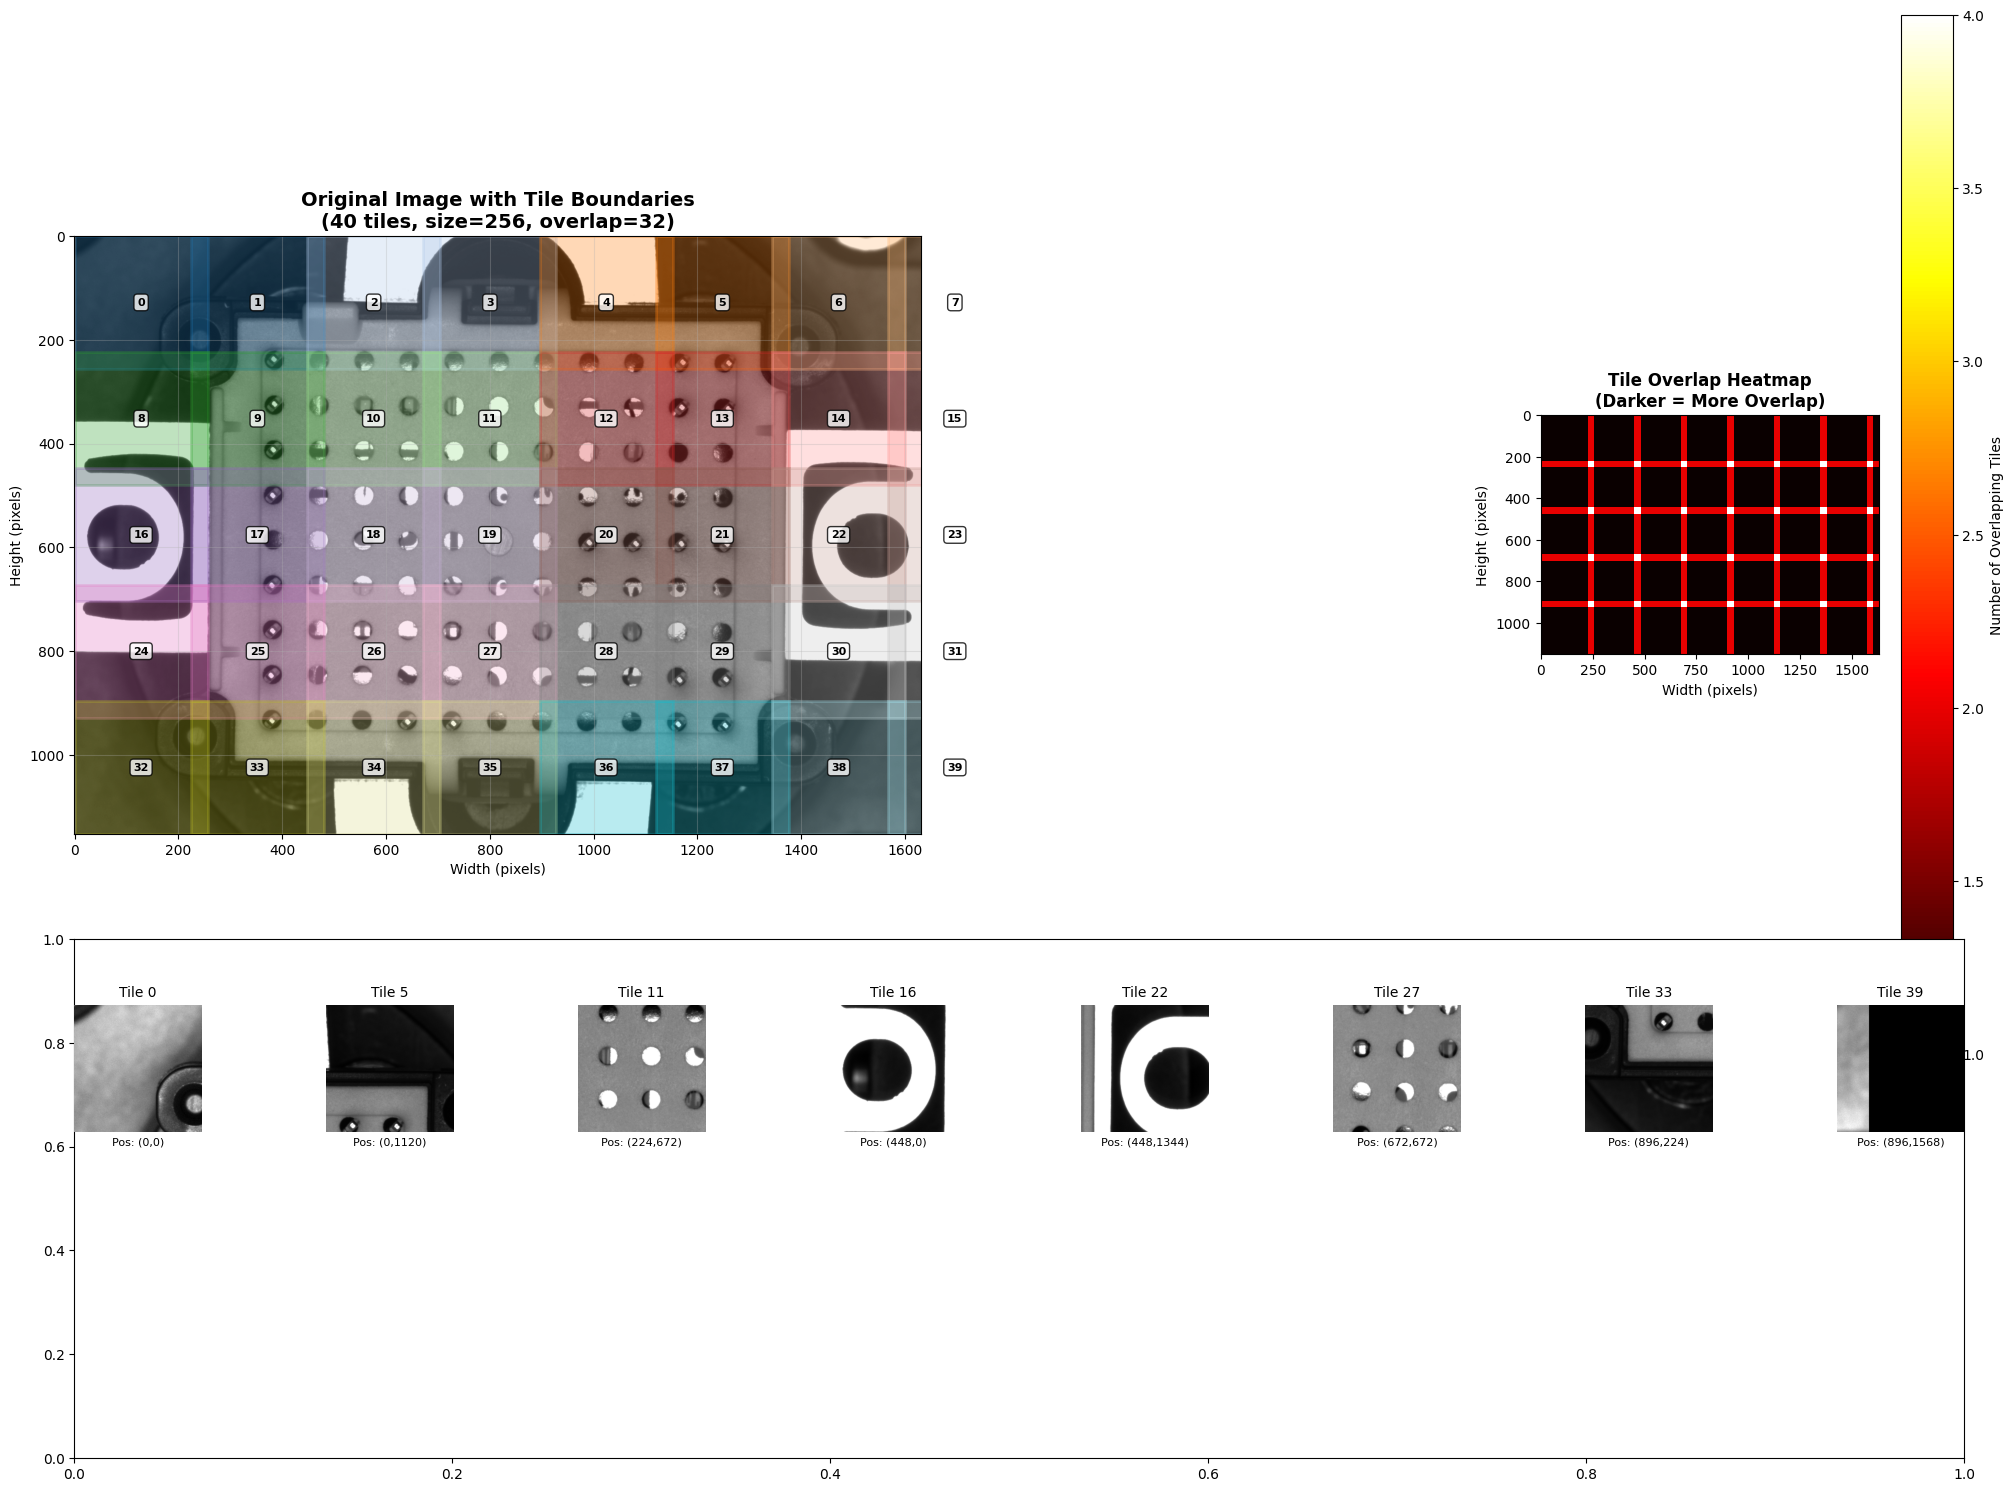

In [55]:
visualize_tile_overlay(
    original_image=sm_img,
    tiles=tiles,
    positions=positions,
    tile_size=256,
    overlap=32,
)

In [57]:
#| export
def visualize_tile_positions(
    image_shape: Tuple[int, int], # shape of the original image (H, W)
    positions: List[Tuple], # list of (row, col, start_h, start_w) for each tile
    tile_size: int = 256, # size of each tile
    figsize: Tuple[int, int] = (12, 8), # figure size
    save_path: Optional[Union[str, Path]] = None # path to save the visualization
) -> None:
    """
    Visualize tile positions as a schematic diagram.
    
    """
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=figsize)
    
    # 1. Tile position schematic
    H, W = image_shape
    colors = plt.cm.tab20(np.linspace(0, 1, len(positions)))
    
    ax1.set_xlim(0, W)
    ax1.set_ylim(H, 0)  # Invert y-axis to match image coordinates
    ax1.set_aspect('equal')
    
    for i, (row, col, start_h, start_w) in enumerate(positions):
        rect = patches.Rectangle(
            (start_w, start_h), tile_size, tile_size,
            linewidth=2, edgecolor=colors[i], facecolor=colors[i], alpha=0.3
        )
        ax1.add_patch(rect)
        
        # Add tile number
        center_x = start_w + tile_size // 2
        center_y = start_h + tile_size // 2
        ax1.text(center_x, center_y, str(i), 
                ha='center', va='center', fontsize=10, fontweight='bold')
    
    ax1.set_title(f'Tile Positions Schematic\n{len(positions)} tiles on {H}×{W} image', 
                  fontsize=12, fontweight='bold')
    ax1.set_xlabel('Width (pixels)')
    ax1.set_ylabel('Height (pixels)')
    ax1.grid(True, alpha=0.3)
    
    # 2. Position statistics
    ax2.axis('off')
    
    # Calculate statistics
    total_pixels = H * W
    tile_pixels = tile_size * tile_size
    coverage_pixels = len(positions) * tile_pixels
    overlap_ratio = (coverage_pixels - total_pixels) / total_pixels if coverage_pixels > total_pixels else 0
    
    stats_text = f"""
    Tile Statistics:
    
    Image Size: {H} x {W} = {total_pixels:,} pixels
    Tile Size: {tile_size} x {tile_size} = {tile_pixels:,} pixels
    Number of Tiles: {len(positions)}
    
    Total Tile Pixels: {coverage_pixels:,}
    Overlap Ratio: {overlap_ratio:.2%}
    
    Position Range:
    Min H: {min(pos[2] for pos in positions)}
    Max H: {max(pos[2] for pos in positions)}
    Min W: {min(pos[3] for pos in positions)}
    Max W: {max(pos[3] for pos in positions)}
    
    Grid Layout:
    Rows: {max(pos[0] for pos in positions) + 1}
    Cols: {max(pos[1] for pos in positions) + 1}
    """
    
    ax2.text(0.1, 0.9, stats_text, transform=ax2.transAxes, 
             fontsize=11, verticalalignment='top', fontfamily='monospace',
             bbox=dict(boxstyle='round,pad=0.5', facecolor='lightgray', alpha=0.8))
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"Tile positions visualization saved to: {save_path}")
    
    plt.show()


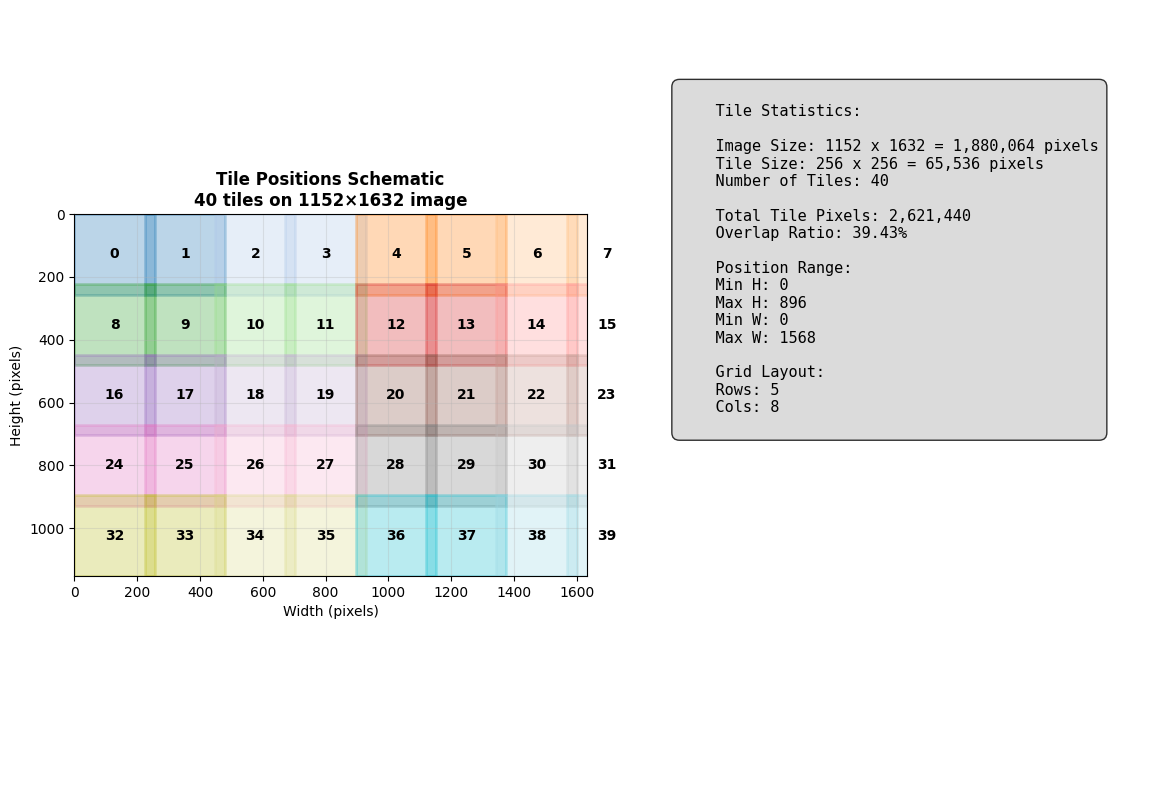

In [51]:
visualize_tile_positions(
    image_shape=(H, W),
    positions=positions,
    tile_size=256,
    figsize=(12, 8),
    save_path=None
)

In [43]:
#| hide
import nbdev; nbdev.nbdev_export()